# Analyze Genetic Algorithm approach

Author: Eric Tran <eric.tran@heig-vd.ch>

In [35]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from DAGGeneratorGA import DAGGeneratorGA
from DAGDatasetGenerator import DAGDatasetGenerator
import copy
import time

# Scale up analysis

In [36]:
# File containing run [33, 40]
# 2025-06-03 08_47_54.025719_dga_scale_run.csv

# File containing run [41, 58]
# 2025-06-05 00_53_32.830428_dga_scale_run.csv

data_files = ["2025-06-03 08_47_54.025719_dga_scale_run.csv", "2025-06-05 00_53_32.830428_dga_scale_run.csv"]
df_results = pd.concat([pd.read_csv(file) for file in data_files], ignore_index=True)
df_results

,n_nodes,perf,run_time,dag
0,33,1627,122.193206,0:26;0:31;26:11;26:19;31:1;11:20;11:29;19:23;1...
1,33,1355,108.007973,0:10;0:15;0:20;10:5;15:22;15:26;20:3;20:32;5:1...
2,33,1449,76.491765,0:17;0:19;0:27;0:28;17:13;19:29;27:14;28:16;13...
3,33,1412,147.521330,0:7;0:19;0:24;7:9;19:16;24:32;9:29;16:18;32:30...
4,33,1488,76.101262,0:8;0:21;8:26;21:29;29:9;29:28;9:5;9:19;28:30;...
...,...,...,...,...
193,58,2583,400.415243,0:45;0:28;0:54;45:47;28:10;54:33;54:17;47:31;4...
194,58,2521,502.622575,0:56;0:35;0:16;56:51;56:3;56:41;35:5;35:20;16:...
195,58,2998,261.591159,0:14;0:17;14:45;17:55;45:4;45:28;55:1;4:37;1:7...
196,58,2938,539.165463,0:55;0:9;55:36;9:50;36:54;50:5;54:14;54:15;5:3...


/tmp/ipykernel_136457/1970895407.py:16: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


<Figure size 640x480 with 0 Axes>

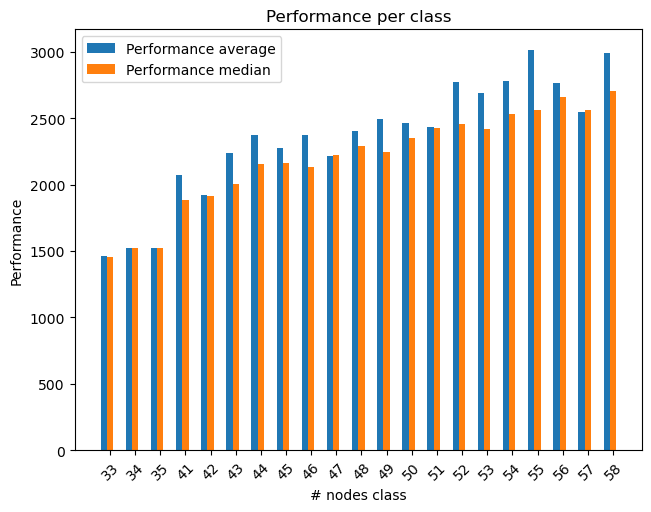

In [37]:
plt.figure()

# Plot results
all_classes = df_results['n_nodes'].unique()
labels = {
    'average': 'Performance average',
    'median': 'Performance median'
}
perfs = {
    'average': [],
    'median': []
}
pos_x = np.arange(len(all_classes))
width_bar = 0.25
fig, ax = plt.subplots(layout='constrained')
plt.tight_layout()
plt.title('Performance per class')
for clazz in all_classes:
    df_class = df_results[df_results['n_nodes'] == clazz]['perf']
    df_mean = df_class.mean()
    df_median = df_class.median()
    perfs['average'].append(df_class.mean())
    perfs['median'].append(df_class.median())

for index, (perf_name, perf) in enumerate(perfs.items()):
    rects = ax.bar(pos_x + width_bar * index, perf, width_bar, label=labels[perf_name])

ax.set_xticks(pos_x + width_bar , all_classes, rotation=45)
ax.set_xlabel('# nodes class')
ax.set_ylabel('Performance')
ax.legend()
plt.show()

/tmp/ipykernel_136457/3998914605.py:16: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


<Figure size 640x480 with 0 Axes>

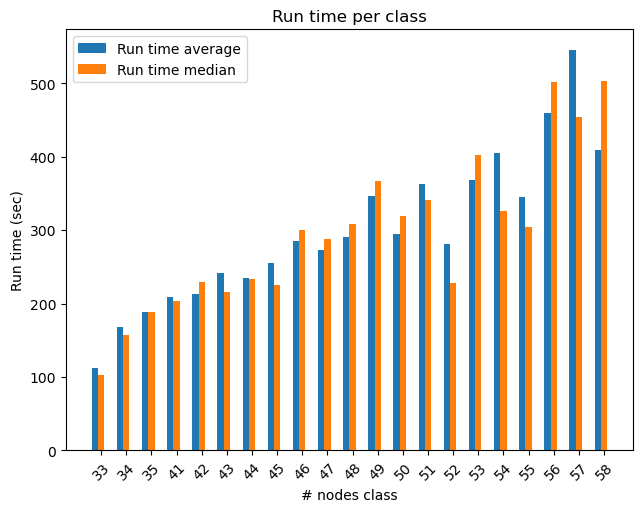

In [38]:
plt.figure()

# Plot results
all_classes = df_results['n_nodes'].unique()
labels = {
    'average': 'Run time average',
    'median': 'Run time median'
}
times = {
    'average': [],
    'median': []
}
pos_x = np.arange(len(all_classes))
width_bar = 0.25
fig, ax = plt.subplots(layout='constrained')
plt.tight_layout()
plt.title('Run time per class')
for clazz in all_classes:
    df_class = df_results[df_results['n_nodes'] == clazz]['run_time']
    df_mean = df_class.mean()
    df_median = df_class.median()
    times['average'].append(df_class.mean())
    times['median'].append(df_class.median())

for index, (name, run_time) in enumerate(times.items()):
    rects = ax.bar(pos_x + width_bar * index, run_time, width_bar, label=labels[name])

ax.set_xticks(pos_x + width_bar , all_classes, rotation=45)
ax.set_xlabel('# nodes class')
ax.set_ylabel('Run time (sec)')
ax.legend()
plt.show()